# Omni-Grid AI-Driven Maintenance Scheduling Optimizer

## Prototype Notebook

This notebook develops a prototype for the **AI-Driven Maintenance Scheduling Optimizer** module of the Omni-Grid platform.

The prototype uses the provided synthetic maintenance scheduling dataset instead of generating a new dataset. The dataset contains daily inverter health, environmental, failure-label, and rolling-feature information. The notebook converts this time-series data into an asset-level maintenance planning snapshot, calculates maintenance priority scores, and creates a constraint-aware maintenance schedule.

## Prototype Objectives

1. Load the provided maintenance scheduling dataset and data dictionary.
2. Check data structure, missing values, and encoding requirements.
3. Convert daily inverter records into a latest asset-level snapshot.
4. Engineer risk, urgency, anomaly, criticality, spare-parts, and feasibility scores.
5. Calculate a maintenance priority score for each inverter.
6. Build a baseline constraint-aware greedy maintenance scheduler.
7. Compare scheduling cost against a simple baseline.
8. Visualize priority distribution, top-risk assets, schedule output, and cost comparison.
9. Export final priority and schedule tables for reporting.


## 1. Import Libraries

We use standard data analysis and visualization libraries. The CSV files can be read using UTF-8. To be safe, the notebook uses `encoding="utf-8-sig"`, which also handles CSV files that may contain a byte-order mark at the beginning.


In [1]:
# Core libraries
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

# Reproducibility
np.random.seed(42)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the Provided Dataset

The folder contains three relevant CSV files:

- `synthetic_maintenance_scheduling_dataset.csv`: full dataset
- `synthetic_maintenance_scheduling_data_dictionary.csv`: column descriptions
- `synthetic_maintenance_schedulingsample.csv`: smaller sample file

For the prototype, we use the full dataset. The sample file is useful only for quick checking.


In [ ]:
from pathlib import Path
import pandas as pd

# ================================================================
# Data paths (portable)
# ================================================================
# Run this notebook from its own module folder. Data lives in ./data.
# If the full synthetic dataset is not present, the sample file is used
# so the notebook still runs end to end for anyone who clones the repo.

DATA_DIR = Path.cwd() / "data"
DATASET_PATH = DATA_DIR / "synthetic_maintenance_scheduling_dataset.csv"
SAMPLE_PATH = DATA_DIR / "synthetic_maintenance_scheduling_sample.csv"
DICTIONARY_PATH = DATA_DIR / "synthetic_maintenance_scheduling_data_dictionary.csv"

if not DATASET_PATH.exists():
    print(f"Full dataset not found, using sample file: {SAMPLE_PATH.name}")
    DATASET_PATH = SAMPLE_PATH

asset_data = pd.read_csv(DATASET_PATH, encoding="utf-8-sig")
data_dictionary = pd.read_csv(DICTIONARY_PATH, encoding="utf-8-sig")
sample_data = pd.read_csv(SAMPLE_PATH, encoding="utf-8-sig")

print("Dataset shape:", asset_data.shape)
print("Data dictionary shape:", data_dictionary.shape)
print("Sample dataset shape:", sample_data.shape)

asset_data.head()

## 3. Data Dictionary

The data dictionary explains what each column means. This is useful before deciding which variables should be used for risk scoring and scheduling.


In [5]:
data_dictionary


,column_name,description
0,date,Observation date
1,inverter_id,Unique inverter identifier
2,manufacturer,Inverter manufacturer
3,climate_zone,Synthetic site climate classification
4,rated_capacity_kw,Rated inverter capacity in kW
5,installation_quality_score,Synthetic installation quality score
6,maintenance_quality_score,Synthetic maintenance quality score
7,age_months,Age of inverter in months
8,ambient_temperature_c,Ambient temperature in Celsius
9,humidity_pct,Humidity percentage


## 4. Dataset Overview and Encoding Check

This section checks column names, data types, missing values, and categorical variables.

Important note: we do **not** need label encoding or one-hot encoding for the current priority scoring and scheduling prototype because we are not training a supervised ML model in this notebook. We only need to parse dates, convert numerical columns properly, and use categorical variables such as `manufacturer` and `climate_zone` for grouping or interpretation.


In [8]:
# Dataset overview
print("Dataset shape:", asset_data.shape)

print("\nColumns:")
print(asset_data.columns.tolist())

print("\nDataset info:")
asset_data.info()

Dataset shape: (32627, 42)

Columns:
['date', 'inverter_id', 'manufacturer', 'climate_zone', 'rated_capacity_kw', 'installation_quality_score', 'maintenance_quality_score', 'age_months', 'ambient_temperature_c', 'humidity_pct', 'dust_soiling_index', 'uv_exposure_index', 'cumulative_uv_exposure', 'operating_hours_today', 'cumulative_operating_hours', 'cumulative_energy_throughput_mwh', 'efficiency_pct', 'reactive_power_capability', 'internal_temperature_c', 'voltage_ripple', 'current_harmonic_distortion_pct', 'insulation_resistance_mohm', 'capacitor_degradation_indicator', 'fan_speed_rpm', 'restart_count_today', 'error_code_count_today', 'thermal_cycling_count_today', 'overload_events_today', 'failure_within_7d', 'failure_within_30d', 'failure_within_90d', 'rul_days', 'failed_today', 'is_censored', 'efficiency_7d_mean', 'efficiency_30d_mean', 'temperature_7d_mean', 'temperature_30d_mean', 'efficiency_decline_7d', 'temp_stress_index', 'restart_7d_sum', 'errors_7d_sum']

Dataset info:
<cl

In [9]:
# Missing values by column
missing_summary = asset_data.isna().sum().sort_values(ascending=False)
missing_summary[missing_summary > 0]


rul_days    17155
dtype: int64

In [11]:
# Check categorical columns
categorical_columns = ["inverter_id", "manufacturer", "climate_zone"]

for col in categorical_columns:
    print(f"\n{col} unique values:")
    print("Number of unique values:", asset_data[col].nunique())
    print("Sample values:", asset_data[col].dropna().unique()[:10])


inverter_id unique values:
Number of unique values: 120
Sample values: ['INV-0001' 'INV-0002' 'INV-0003' 'INV-0004' 'INV-0005' 'INV-0006'
 'INV-0007' 'INV-0008' 'INV-0009' 'INV-0010']

manufacturer unique values:
Number of unique values: 4
Sample values: ['Fronius' 'SolarEdge' 'Huawei' 'SMA']

climate_zone unique values:
Number of unique values: 4
Sample values: ['Temperate' 'Coastal' 'Hot-Dry' 'Humid-Subtropical']


## 5. Initial Data Preparation

The dataset is daily time-series data for multiple inverters. Since maintenance scheduling needs one current maintenance decision per asset, we convert the dataset into a latest asset-level snapshot.

Steps:

1. Convert `date` into a datetime column.
2. Convert numeric columns into numeric data types.
3. Sort records by inverter and date.
4. Keep the latest available record for each inverter.

The missing values in `rul_days` are expected because censored assets have not failed within the observation window. For scheduling, blank RUL values are treated as lower urgency.


In [12]:
# Convert date column
asset_data["date"] = pd.to_datetime(asset_data["date"])

# Convert all non-categorical columns to numeric where possible
categorical_base_cols = ["date", "inverter_id", "manufacturer", "climate_zone"]

for col in asset_data.columns:
    if col not in categorical_base_cols:
        asset_data[col] = pd.to_numeric(asset_data[col], errors="coerce")

# Sort by inverter and date
asset_data = asset_data.sort_values(["inverter_id", "date"]).reset_index(drop=True)

# Create latest snapshot per inverter
latest_snapshot = (
    asset_data
    .groupby("inverter_id", as_index=False)
    .tail(1)
    .copy()
    .reset_index(drop=True)
)

print("Original daily dataset shape:", asset_data.shape)
print("Latest asset-level snapshot shape:", latest_snapshot.shape)

latest_snapshot.head()


Original daily dataset shape: (32627, 42)
Latest asset-level snapshot shape: (120, 42)


,date,inverter_id,manufacturer,climate_zone,rated_capacity_kw,installation_quality_score,maintenance_quality_score,age_months,ambient_temperature_c,humidity_pct,dust_soiling_index,uv_exposure_index,cumulative_uv_exposure,operating_hours_today,cumulative_operating_hours,cumulative_energy_throughput_mwh,efficiency_pct,reactive_power_capability,internal_temperature_c,voltage_ripple,current_harmonic_distortion_pct,insulation_resistance_mohm,capacitor_degradation_indicator,fan_speed_rpm,restart_count_today,error_code_count_today,thermal_cycling_count_today,overload_events_today,failure_within_7d,failure_within_30d,failure_within_90d,rul_days,failed_today,is_censored,efficiency_7d_mean,efficiency_30d_mean,temperature_7d_mean,temperature_30d_mean,efficiency_decline_7d,temp_stress_index,restart_7d_sum,errors_7d_sum
0,2025-05-08,INV-0001,Fronius,Temperate,100,0.789,0.880,87.23,25.43,56.31,0.453,9.11,819.83,13.21,1504.26,132.795,89.52,0.843,43.68,4.432,8.275,71.83,0.980,1853.5,3,2,7,1,1,1,1,0.0,1,0,90.037143,91.230667,42.185714,41.740333,-0.517143,3.68,11.0,24.0
1,2025-12-31,INV-0002,SolarEdge,Coastal,50,0.879,0.760,79.13,28.43,65.05,0.175,6.83,2238.92,12.60,4203.72,192.062,98.46,1.005,40.35,2.813,4.553,82.25,0.481,2395.7,0,0,1,0,0,0,0,NaN,0,1,97.707143,97.924000,35.255714,34.044667,0.752857,0.35,0.0,3.0
2,2025-10-31,INV-0003,Huawei,Hot-Dry,100,0.798,0.982,44.10,35.40,18.84,0.656,6.11,1908.59,12.01,3462.68,307.726,90.13,0.855,48.02,3.745,6.091,78.83,0.903,2236.2,0,6,9,1,1,1,1,0.0,1,0,90.111429,91.148000,45.971429,45.728333,0.018571,8.02,10.0,16.0
3,2025-12-31,INV-0004,SMA,Coastal,75,0.822,0.757,78.13,20.72,65.98,0.286,5.43,2313.65,11.33,4199.83,288.781,98.60,0.984,29.72,2.595,5.469,83.68,0.323,2471.6,0,0,2,0,0,0,0,NaN,0,1,97.995714,97.978000,33.527143,35.979667,0.604286,0.00,3.0,1.0
4,2025-05-07,INV-0005,Huawei,Temperate,150,0.811,0.822,124.20,21.13,53.07,0.235,5.65,782.25,12.21,1446.71,184.522,90.24,0.823,38.54,4.838,10.196,62.87,1.000,1869.9,0,1,8,2,1,1,1,0.0,1,0,90.370000,91.049667,42.497143,41.944333,-0.130000,0.00,10.0,22.0


In [13]:
# Fill RUL for scheduling logic only.
# Blank RUL means the asset is censored / not observed to fail, so we treat it as lower urgency.
latest_snapshot["rul_days_filled"] = latest_snapshot["rul_days"].fillna(365)

latest_snapshot[["inverter_id", "date", "rul_days", "rul_days_filled", "is_censored"]].head(10)


,inverter_id,date,rul_days,rul_days_filled,is_censored
0,INV-0001,2025-05-08,0.0,0.0,0
1,INV-0002,2025-12-31,NaN,365.0,1
2,INV-0003,2025-10-31,0.0,0.0,0
3,INV-0004,2025-12-31,NaN,365.0,1
4,INV-0005,2025-05-07,0.0,0.0,0
5,INV-0006,2025-05-15,0.0,0.0,0
6,INV-0007,2025-12-31,NaN,365.0,1
7,INV-0008,2025-12-31,NaN,365.0,1
8,INV-0009,2025-12-21,0.0,0.0,0
9,INV-0010,2025-05-30,0.0,0.0,0


## 6. Helper Function for Normalization

Many scoring components need to be converted to a common 0 to 1 scale. A value closer to 1 means higher risk, higher importance, or higher urgency depending on the feature.


In [14]:
def minmax(series):
    """
    Min-max normalize a pandas Series to the 0-1 range.
    Returns 0 if the series has no variation.
    """
    s = series.astype(float)
    denominator = s.max() - s.min()

    if pd.isna(denominator) or denominator == 0:
        return pd.Series(np.zeros(len(s)), index=s.index)

    return (s - s.min()) / denominator

print("Helper function created successfully.")


Helper function created successfully.


## 7. Risk Feature Engineering

The dataset does not directly contain a model-generated probability score. Therefore, for this prototype, we create a synthetic failure probability score using inverter health indicators.

This score represents the type of output that would normally come from the predictive maintenance model.


In [15]:
# Basic normalized risk signals
latest_snapshot["capacity_score"] = minmax(latest_snapshot["rated_capacity_kw"])
latest_snapshot["age_score"] = minmax(latest_snapshot["age_months"])
latest_snapshot["efficiency_loss_score"] = minmax(100 - latest_snapshot["efficiency_pct"])
latest_snapshot["temperature_risk_score"] = minmax(latest_snapshot["internal_temperature_c"])
latest_snapshot["temp_stress_score"] = minmax(latest_snapshot["temp_stress_index"])
latest_snapshot["voltage_ripple_score"] = minmax(latest_snapshot["voltage_ripple"])
latest_snapshot["thd_score"] = minmax(latest_snapshot["current_harmonic_distortion_pct"])
latest_snapshot["capacitor_risk_score"] = latest_snapshot["capacitor_degradation_indicator"].clip(0, 1)
latest_snapshot["insulation_risk_score"] = 1 - minmax(latest_snapshot["insulation_resistance_mohm"])
latest_snapshot["restart_error_score"] = minmax(
    latest_snapshot["restart_7d_sum"] + latest_snapshot["errors_7d_sum"]
)
latest_snapshot["maintenance_quality_risk"] = 1 - latest_snapshot["maintenance_quality_score"]

latest_snapshot[[
    "inverter_id", "capacity_score", "age_score", "efficiency_loss_score",
    "temperature_risk_score", "capacitor_risk_score", "restart_error_score"
]].head()


,inverter_id,capacity_score,age_score,efficiency_loss_score,temperature_risk_score,capacitor_risk_score,restart_error_score
0,INV-0001,0.250,0.622625,0.928994,0.594825,0.980,0.777778
1,INV-0002,0.000,0.552996,0.047337,0.511178,0.481,0.066667
2,INV-0003,0.250,0.251870,0.868836,0.703843,0.903,0.577778
3,INV-0004,0.125,0.544400,0.033531,0.244160,0.323,0.088889
4,INV-0005,0.500,0.940428,0.857988,0.465712,1.000,0.711111


## 8. Asset Criticality Score

Asset criticality represents how important an inverter is from an operational perspective.

In this prototype, criticality is estimated from:

- Rated capacity
- Asset age
- Maintenance quality risk

A high-capacity, older, poorly maintained inverter receives a higher criticality score.


In [16]:
latest_snapshot["asset_criticality_score"] = (
    0.45 * latest_snapshot["capacity_score"] +
    0.30 * latest_snapshot["age_score"] +
    0.25 * latest_snapshot["maintenance_quality_risk"]
).clip(0, 1).round(3)

latest_snapshot[[
    "inverter_id", "rated_capacity_kw", "age_months",
    "maintenance_quality_score", "asset_criticality_score"
]].sort_values("asset_criticality_score", ascending=False).head(10)


,inverter_id,rated_capacity_kw,age_months,maintenance_quality_score,asset_criticality_score
41,INV-0042,250,131.13,0.739,0.815
85,INV-0086,250,129.13,0.950,0.757
78,INV-0079,250,104.13,0.847,0.719
84,INV-0085,250,90.60,0.735,0.712
36,INV-0037,250,94.70,0.820,0.701
58,INV-0059,250,82.63,0.733,0.692
51,INV-0052,250,105.13,0.977,0.689
65,INV-0066,250,98.13,0.948,0.678
117,INV-0118,250,74.13,0.734,0.670
28,INV-0029,250,87.50,0.894,0.664


## 9. Failure Probability Score

The failure probability score is a synthetic risk signal created from the latest inverter condition. In a real system, this would come from the predictive maintenance model.

We intentionally do not use `failure_within_30d` to calculate this score because that column is a future label. The future label can be used later for evaluation, but not as an input to the risk score.


In [17]:
latest_snapshot["failure_probability_30d"] = (
    0.22 * latest_snapshot["capacitor_risk_score"] +
    0.15 * latest_snapshot["temperature_risk_score"] +
    0.12 * latest_snapshot["temp_stress_score"] +
    0.12 * latest_snapshot["voltage_ripple_score"] +
    0.12 * latest_snapshot["thd_score"] +
    0.12 * latest_snapshot["insulation_risk_score"] +
    0.10 * latest_snapshot["restart_error_score"] +
    0.05 * latest_snapshot["efficiency_loss_score"]
).clip(0, 1).round(3)

latest_snapshot[[
    "inverter_id", "failure_probability_30d", "capacitor_risk_score",
    "temperature_risk_score", "restart_error_score", "efficiency_loss_score"
]].sort_values("failure_probability_30d", ascending=False).head(10)


,inverter_id,failure_probability_30d,capacitor_risk_score,temperature_risk_score,restart_error_score,efficiency_loss_score
95,INV-0096,0.791,0.920,0.782467,0.777778,0.910256
68,INV-0069,0.791,1.000,0.794022,0.888889,0.839250
43,INV-0044,0.785,1.000,0.614670,0.688889,0.835306
105,INV-0106,0.780,0.819,0.866616,0.800000,0.807692
13,INV-0014,0.770,0.897,0.698066,0.844444,0.988166
84,INV-0085,0.767,1.000,0.668174,0.955556,0.781065
86,INV-0087,0.766,0.931,0.699071,0.533333,0.916174
108,INV-0109,0.755,0.835,1.000000,0.600000,0.843195
52,INV-0053,0.754,0.851,0.950515,0.688889,0.805720
66,INV-0067,0.754,0.765,0.868124,1.000000,0.818540


## 10. RUL Urgency Score

Remaining Useful Life tells us how long an inverter is expected to continue operating before failure.

Lower RUL means higher urgency. Missing RUL values are treated as low urgency because they represent censored assets in this dataset.


In [18]:
def calculate_rul_urgency(rul_days):
    """
    Convert RUL days into an urgency score.
    Lower RUL means higher maintenance urgency.
    """
    if pd.isna(rul_days):
        return 0.10
    elif rul_days <= 7:
        return 1.00
    elif rul_days <= 14:
        return 0.85
    elif rul_days <= 30:
        return 0.70
    elif rul_days <= 90:
        return 0.40
    else:
        return 0.10

latest_snapshot["rul_urgency_score"] = latest_snapshot["rul_days"].apply(calculate_rul_urgency)

latest_snapshot[["inverter_id", "rul_days", "rul_urgency_score", "is_censored"]].head(10)


,inverter_id,rul_days,rul_urgency_score,is_censored
0,INV-0001,0.0,1.0,0
1,INV-0002,NaN,0.1,1
2,INV-0003,0.0,1.0,0
3,INV-0004,NaN,0.1,1
4,INV-0005,0.0,1.0,0
5,INV-0006,0.0,1.0,0
6,INV-0007,NaN,0.1,1
7,INV-0008,NaN,0.1,1
8,INV-0009,0.0,1.0,0
9,INV-0010,0.0,1.0,0


## 11. Anomaly Score and Severity

The anomaly score represents unusual current behaviour. It is created from stress, voltage ripple, harmonic distortion, errors, restarts, and efficiency loss.

In a production system, this score would come from the anomaly detection model.


In [19]:
latest_snapshot["anomaly_score"] = (
    0.25 * latest_snapshot["temp_stress_score"] +
    0.20 * latest_snapshot["voltage_ripple_score"] +
    0.20 * latest_snapshot["thd_score"] +
    0.20 * latest_snapshot["restart_error_score"] +
    0.15 * latest_snapshot["efficiency_loss_score"]
).clip(0, 1).round(3)

def categorize_anomaly(score):
    if score >= 0.80:
        return "Critical"
    elif score >= 0.60:
        return "High"
    elif score >= 0.40:
        return "Medium"
    elif score >= 0.20:
        return "Low"
    else:
        return "Normal"

latest_snapshot["anomaly_severity"] = latest_snapshot["anomaly_score"].apply(categorize_anomaly)

latest_snapshot[["inverter_id", "anomaly_score", "anomaly_severity"]].sort_values(
    "anomaly_score", ascending=False
).head(10)


,inverter_id,anomaly_score,anomaly_severity
66,INV-0067,0.757,High
68,INV-0069,0.746,High
105,INV-0106,0.737,High
13,INV-0014,0.735,High
95,INV-0096,0.731,High
108,INV-0109,0.725,High
52,INV-0053,0.724,High
86,INV-0087,0.698,High
84,INV-0085,0.692,High
5,INV-0006,0.687,High


## 12. Production Loss Risk

Production loss risk estimates how damaging it would be if the inverter failed or had to be taken offline.

For this prototype, production loss risk is based on rated capacity and asset criticality.


In [20]:
latest_snapshot["production_loss_risk"] = (
    0.65 * latest_snapshot["capacity_score"] +
    0.35 * latest_snapshot["asset_criticality_score"]
).clip(0, 1).round(3)

latest_snapshot[[
    "inverter_id", "rated_capacity_kw", "asset_criticality_score", "production_loss_risk"
]].sort_values("production_loss_risk", ascending=False).head(10)


,inverter_id,rated_capacity_kw,asset_criticality_score,production_loss_risk
41,INV-0042,250,0.815,0.935
85,INV-0086,250,0.757,0.915
78,INV-0079,250,0.719,0.902
84,INV-0085,250,0.712,0.899
36,INV-0037,250,0.701,0.895
58,INV-0059,250,0.692,0.892
51,INV-0052,250,0.689,0.891
65,INV-0066,250,0.678,0.887
117,INV-0118,250,0.670,0.885
28,INV-0029,250,0.664,0.882


## 13. Spare Parts and Required Skills

The dataset does not directly include spare-parts or crew-skill columns. For the scheduling prototype, we derive them from the most likely risk driver.

This allows the notebook to simulate a practical maintenance scheduling environment without inventing a completely separate dataset.


In [21]:
def choose_required_part(row):
    """
    Assign a likely required part based on the dominant inverter health issue.
    """
    if row["capacitor_risk_score"] >= 0.70:
        return "Capacitor Kit"
    elif row["internal_temperature_c"] >= 45 or row["fan_speed_rpm"] >= 3300:
        return "Cooling Fan"
    elif row["restart_error_score"] >= 0.60:
        return "Control Board"
    elif row["insulation_risk_score"] >= 0.70:
        return "Insulation Kit"
    elif row["voltage_ripple_score"] >= 0.70:
        return "DC Switch"
    else:
        return "Inspection Only"

def skill_from_part(part):
    """
    Map required part or task type to required crew skill.
    """
    if part in ["Capacitor Kit", "DC Switch", "Insulation Kit"]:
        return "Electrical"
    elif part == "Cooling Fan":
        return "Thermal Inspection"
    elif part == "Control Board":
        return "Control Systems"
    else:
        return "General Maintenance"

latest_snapshot["required_part"] = latest_snapshot.apply(choose_required_part, axis=1)
latest_snapshot["required_skill"] = latest_snapshot["required_part"].apply(skill_from_part)

latest_snapshot[["inverter_id", "required_part", "required_skill"]].head(10)


,inverter_id,required_part,required_skill
0,INV-0001,Capacitor Kit,Electrical
1,INV-0002,Inspection Only,General Maintenance
2,INV-0003,Capacitor Kit,Electrical
3,INV-0004,Inspection Only,General Maintenance
4,INV-0005,Capacitor Kit,Electrical
5,INV-0006,Capacitor Kit,Electrical
6,INV-0007,Inspection Only,General Maintenance
7,INV-0008,Inspection Only,General Maintenance
8,INV-0009,Capacitor Kit,Electrical
9,INV-0010,Capacitor Kit,Electrical


In [22]:
# Simulate spare part availability based on part type
part_status_options = {
    "Capacitor Kit": ["Available Now", "Available in 3 Days", "Available in 7 Days", "Unavailable"],
    "Cooling Fan": ["Available Now", "Available in 3 Days", "Available in 7 Days", "Unavailable"],
    "Control Board": ["Available Now", "Available in 3 Days", "Available in 7 Days", "Unavailable"],
    "Insulation Kit": ["Available Now", "Available in 3 Days", "Available in 7 Days", "Unavailable"],
    "DC Switch": ["Available Now", "Available in 3 Days", "Available in 7 Days", "Unavailable"],
    "Inspection Only": ["Available Now"]
}

part_status_probabilities = {
    "Capacitor Kit": [0.50, 0.25, 0.15, 0.10],
    "Cooling Fan": [0.60, 0.20, 0.15, 0.05],
    "Control Board": [0.35, 0.25, 0.25, 0.15],
    "Insulation Kit": [0.40, 0.25, 0.20, 0.15],
    "DC Switch": [0.45, 0.30, 0.15, 0.10],
    "Inspection Only": [1.00]
}

latest_snapshot["part_status"] = latest_snapshot["required_part"].apply(
    lambda part: np.random.choice(part_status_options[part], p=part_status_probabilities[part])
)

readiness_map = {
    "Available Now": 1.00,
    "Available in 3 Days": 0.70,
    "Available in 7 Days": 0.40,
    "Unavailable": 0.00
}

latest_snapshot["spare_parts_readiness"] = latest_snapshot["part_status"].map(readiness_map)

latest_snapshot[["inverter_id", "required_part", "part_status", "spare_parts_readiness"]].head(10)


,inverter_id,required_part,part_status,spare_parts_readiness
0,INV-0001,Capacitor Kit,Available Now,1.0
1,INV-0002,Inspection Only,Available Now,1.0
2,INV-0003,Capacitor Kit,Available in 3 Days,0.7
3,INV-0004,Inspection Only,Available Now,1.0
4,INV-0005,Capacitor Kit,Available Now,1.0
5,INV-0006,Capacitor Kit,Available Now,1.0
6,INV-0007,Inspection Only,Available Now,1.0
7,INV-0008,Inspection Only,Available Now,1.0
8,INV-0009,Capacitor Kit,Available in 3 Days,0.7
9,INV-0010,Capacitor Kit,Available in 3 Days,0.7


## 14. Maintenance Feasibility Score

Maintenance feasibility estimates how easy it is to schedule the maintenance task soon.

For this prototype, it combines:

- Weather workability
- Spare-parts readiness
- Maintenance quality score


In [23]:
# Basic weather workability rule
latest_snapshot["weather_workability_score"] = np.where(
    (latest_snapshot["ambient_temperature_c"].between(10, 38)) &
    (latest_snapshot["humidity_pct"] <= 90),
    1.00,
    0.60
)

latest_snapshot["maintenance_feasibility_score"] = (
    0.45 * latest_snapshot["weather_workability_score"] +
    0.35 * latest_snapshot["spare_parts_readiness"] +
    0.20 * latest_snapshot["maintenance_quality_score"]
).clip(0, 1).round(3)

latest_snapshot[[
    "inverter_id", "weather_workability_score", "spare_parts_readiness",
    "maintenance_quality_score", "maintenance_feasibility_score"
]].head(10)


,inverter_id,weather_workability_score,spare_parts_readiness,maintenance_quality_score,maintenance_feasibility_score
0,INV-0001,1.0,1.0,0.880,0.976
1,INV-0002,1.0,1.0,0.760,0.952
2,INV-0003,1.0,0.7,0.982,0.891
3,INV-0004,1.0,1.0,0.757,0.951
4,INV-0005,1.0,1.0,0.822,0.964
5,INV-0006,0.6,1.0,0.780,0.776
6,INV-0007,1.0,1.0,0.711,0.942
7,INV-0008,1.0,1.0,0.889,0.978
8,INV-0009,1.0,0.7,0.756,0.846
9,INV-0010,1.0,0.7,0.955,0.886


## 15. Maintenance Priority Score

The maintenance priority score combines predictive risk, RUL urgency, anomaly severity, criticality, production loss, feasibility, and spare-parts readiness.

The result is a score between 0 and 100. A higher score means the inverter should be scheduled earlier.


In [24]:
latest_snapshot["priority_score"] = 100 * (
    0.25 * latest_snapshot["failure_probability_30d"] +
    0.20 * latest_snapshot["rul_urgency_score"] +
    0.15 * latest_snapshot["anomaly_score"] +
    0.15 * latest_snapshot["asset_criticality_score"] +
    0.10 * latest_snapshot["production_loss_risk"] +
    0.10 * latest_snapshot["maintenance_feasibility_score"] +
    0.05 * latest_snapshot["spare_parts_readiness"]
)

latest_snapshot["priority_score"] = latest_snapshot["priority_score"].round(2)

def assign_priority_category(score):
    if score >= 85:
        return "Critical"
    elif score >= 70:
        return "High"
    elif score >= 50:
        return "Medium"
    elif score >= 30:
        return "Low"
    else:
        return "Normal"

latest_snapshot["priority_category"] = latest_snapshot["priority_score"].apply(assign_priority_category)

ranked_assets = latest_snapshot.sort_values("priority_score", ascending=False).reset_index(drop=True)

ranked_assets[[
    "inverter_id", "manufacturer", "climate_zone", "priority_score", "priority_category",
    "failure_probability_30d", "rul_days", "anomaly_score", "required_part", "part_status"
]].head(15)


,inverter_id,manufacturer,climate_zone,priority_score,priority_category,failure_probability_30d,rul_days,anomaly_score,required_part,part_status
0,INV-0086,Fronius,Temperate,84.04,High,0.752,1.0,0.656,Capacitor Kit,Available Now
1,INV-0085,Huawei,Hot-Dry,83.70,High,0.767,0.0,0.692,Capacitor Kit,Available Now
2,INV-0059,SMA,Hot-Dry,81.01,High,0.690,0.0,0.666,Capacitor Kit,Available Now
3,INV-0037,SolarEdge,Humid-Subtropical,79.10,High,0.668,0.0,0.553,Capacitor Kit,Available Now
4,INV-0006,SMA,Coastal,78.39,High,0.721,0.0,0.687,Capacitor Kit,Available Now
5,INV-0096,Fronius,Hot-Dry,78.08,High,0.791,0.0,0.731,Capacitor Kit,Available Now
6,INV-0029,SMA,Hot-Dry,76.94,High,0.685,0.0,0.586,Capacitor Kit,Available in 3 Days
7,INV-0005,Huawei,Temperate,75.72,High,0.728,0.0,0.628,Capacitor Kit,Available Now
8,INV-0078,SMA,Humid-Subtropical,75.37,High,0.607,0.0,0.522,Capacitor Kit,Available Now
9,INV-0084,Huawei,Hot-Dry,74.27,High,0.709,0.0,0.617,Capacitor Kit,Available Now


## 16. Interpretation of Priority Results

The priority score gives maintenance teams a business-friendly ranking. Assets with high failure risk, low RUL, abnormal behaviour, high criticality, and strong production-loss impact rise to the top.

This stage converts technical model outputs into a practical maintenance priority table.


In [25]:
# Priority category summary
priority_summary = ranked_assets["priority_category"].value_counts().reindex(
    ["Critical", "High", "Medium", "Low", "Normal"], fill_value=0
)

priority_summary


priority_category
Critical     0
High        19
Medium      54
Low         35
Normal      12
Name: count, dtype: int64

## 17. Create Repair Time and Cost Estimates

The dataset does not directly provide maintenance cost or repair duration. For scheduling, we create estimated values using capacity, risk, and anomaly severity.

In production, these values would come from ERP, CMMS, or historical work-order systems.


In [26]:
ranked_assets["estimated_repair_hours"] = np.ceil(
    2 +
    2 * ranked_assets["capacity_score"] +
    2 * ranked_assets["failure_probability_30d"] +
    1 * ranked_assets["anomaly_score"]
).astype(int)

ranked_assets["maintenance_cost"] = (
    800 +
    ranked_assets["rated_capacity_kw"] * 8 +
    ranked_assets["estimated_repair_hours"] * 250 +
    ranked_assets["failure_probability_30d"] * 3000
).round(0).astype(int)

ranked_assets["downtime_cost_per_hour"] = (
    ranked_assets["rated_capacity_kw"] * ranked_assets["production_loss_risk"] * 8
).round(0).astype(int)

ranked_assets[[
    "inverter_id", "priority_score", "estimated_repair_hours",
    "maintenance_cost", "downtime_cost_per_hour"
]].head(10)


,inverter_id,priority_score,estimated_repair_hours,maintenance_cost,downtime_cost_per_hour
0,INV-0086,84.04,7,6806,1830
1,INV-0085,83.70,7,6851,1798
2,INV-0059,81.01,7,6620,1784
3,INV-0037,79.10,6,6304,1790
4,INV-0006,78.39,7,6713,1708
5,INV-0096,78.08,6,5873,606
6,INV-0029,76.94,6,6355,1764
7,INV-0005,75.72,6,5684,622
8,INV-0078,75.37,6,6121,1720
9,INV-0084,74.27,6,5627,607


## 18. Define Crew Availability

This section creates a small synthetic crew table for the prototype. Each crew has a primary skill and daily work-hour capacity.

In production, this information would come from a workforce management or maintenance planning system.


In [27]:
crews = pd.DataFrame({
    "crew_id": ["Crew A", "Crew B", "Crew C", "Crew D", "Crew E", "Crew F"],
    "primary_skill": [
        "Electrical", "Thermal Inspection", "Control Systems",
        "General Maintenance", "Electrical", "Thermal Inspection"
    ],
    "daily_capacity_hours": [8, 8, 8, 8, 8, 8]
})

crews


,crew_id,primary_skill,daily_capacity_hours
0,Crew A,Electrical,8
1,Crew B,Thermal Inspection,8
2,Crew C,Control Systems,8
3,Crew D,General Maintenance,8
4,Crew E,Electrical,8
5,Crew F,Thermal Inspection,8


## 19. Greedy Maintenance Scheduler

The greedy scheduler creates a practical baseline maintenance plan.

Logic:

1. Select assets with priority score of 30 or above.
2. Sort tasks by priority score.
3. Check spare-part availability.
4. Find the earliest available crew with the required skill.
5. Schedule the task if crew capacity is available.
6. Defer the task if parts or crew slots are unavailable.


In [28]:
# Select tasks for the 14-day scheduling horizon
maintenance_tasks = ranked_assets[ranked_assets["priority_score"] >= 30].copy()
maintenance_tasks = maintenance_tasks.head(40).reset_index(drop=True)

# Planning horizon starts after the latest dataset date
start_date = asset_data["date"].max() + pd.Timedelta(days=1)
planning_days = 14
planning_dates = pd.date_range(start=start_date, periods=planning_days, freq="D")

print("Scheduling horizon:", planning_dates.min().date(), "to", planning_dates.max().date())
print("Number of maintenance tasks selected:", len(maintenance_tasks))


Scheduling horizon: 2026-01-01 to 2026-01-14
Number of maintenance tasks selected: 40


In [29]:
def earliest_part_date(status):
    """
    Convert part availability status into earliest feasible maintenance date.
    """
    if status == "Available Now":
        return start_date
    elif status == "Available in 3 Days":
        return start_date + pd.Timedelta(days=3)
    elif status == "Available in 7 Days":
        return start_date + pd.Timedelta(days=7)
    else:
        return None

# Track used crew hours by day
crew_schedule = {
    (crew, date): 0
    for crew in crews["crew_id"]
    for date in planning_dates
}

scheduled_records = []
deferred_records = []

for _, task in maintenance_tasks.iterrows():
    part_date = earliest_part_date(task["part_status"])

    if part_date is None:
        deferred_records.append({
            "inverter_id": task["inverter_id"],
            "priority_score": task["priority_score"],
            "required_part": task["required_part"],
            "reason": "Required part unavailable"
        })
        continue

    assigned = False
    eligible_crews = crews[crews["primary_skill"].isin([task["required_skill"], "General Maintenance"])]

    for date in planning_dates:
        if date < part_date:
            continue

        for _, crew in eligible_crews.iterrows():
            used_hours = crew_schedule[(crew["crew_id"], date)]

            if used_hours + task["estimated_repair_hours"] <= crew["daily_capacity_hours"]:
                start_hour = 8 + used_hours
                end_hour = start_hour + task["estimated_repair_hours"]
                crew_schedule[(crew["crew_id"], date)] = used_hours + task["estimated_repair_hours"]

                scheduled_records.append({
                    "scheduled_date": date.date(),
                    "start_time": f"{start_hour:02.0f}:00",
                    "end_time": f"{end_hour:02.0f}:00",
                    "crew_id": crew["crew_id"],
                    "inverter_id": task["inverter_id"],
                    "manufacturer": task["manufacturer"],
                    "climate_zone": task["climate_zone"],
                    "required_skill": task["required_skill"],
                    "required_part": task["required_part"],
                    "part_status": task["part_status"],
                    "estimated_repair_hours": task["estimated_repair_hours"],
                    "priority_score": task["priority_score"],
                    "priority_category": task["priority_category"],
                    "failure_probability_30d": task["failure_probability_30d"],
                    "rul_days": task["rul_days"],
                    "reason": (
                        f"{task['priority_category']} priority: "
                        f"risk={task['failure_probability_30d']:.2f}, "
                        f"anomaly={task['anomaly_score']:.2f}, "
                        f"RUL={task['rul_days_filled']:.0f} days"
                    )
                })
                assigned = True
                break

        if assigned:
            break

    if not assigned:
        deferred_records.append({
            "inverter_id": task["inverter_id"],
            "priority_score": task["priority_score"],
            "required_part": task["required_part"],
            "reason": "No feasible crew slot within planning horizon"
        })

schedule_df = pd.DataFrame(scheduled_records)
deferred_df = pd.DataFrame(deferred_records)

print("Scheduled tasks:", len(schedule_df))
print("Deferred tasks:", len(deferred_df))

schedule_df.head(10)


Scheduled tasks: 39
Deferred tasks: 1


,scheduled_date,start_time,end_time,crew_id,inverter_id,manufacturer,climate_zone,required_skill,required_part,part_status,estimated_repair_hours,priority_score,priority_category,failure_probability_30d,rul_days,reason
0,2026-01-01,08:00,15:00,Crew A,INV-0086,Fronius,Temperate,Electrical,Capacitor Kit,Available Now,7,84.04,High,0.752,1.0,"High priority: risk=0.75, anomaly=0.66, RUL=1 ..."
1,2026-01-01,08:00,15:00,Crew D,INV-0085,Huawei,Hot-Dry,Electrical,Capacitor Kit,Available Now,7,83.70,High,0.767,0.0,"High priority: risk=0.77, anomaly=0.69, RUL=0 ..."
2,2026-01-01,08:00,15:00,Crew E,INV-0059,SMA,Hot-Dry,Electrical,Capacitor Kit,Available Now,7,81.01,High,0.690,0.0,"High priority: risk=0.69, anomaly=0.67, RUL=0 ..."
3,2026-01-02,08:00,14:00,Crew A,INV-0037,SolarEdge,Humid-Subtropical,Electrical,Capacitor Kit,Available Now,6,79.10,High,0.668,0.0,"High priority: risk=0.67, anomaly=0.55, RUL=0 ..."
4,2026-01-02,08:00,15:00,Crew D,INV-0006,SMA,Coastal,Electrical,Capacitor Kit,Available Now,7,78.39,High,0.721,0.0,"High priority: risk=0.72, anomaly=0.69, RUL=0 ..."
5,2026-01-02,08:00,14:00,Crew E,INV-0096,Fronius,Hot-Dry,Electrical,Capacitor Kit,Available Now,6,78.08,High,0.791,0.0,"High priority: risk=0.79, anomaly=0.73, RUL=0 ..."
6,2026-01-04,08:00,14:00,Crew A,INV-0029,SMA,Hot-Dry,Electrical,Capacitor Kit,Available in 3 Days,6,76.94,High,0.685,0.0,"High priority: risk=0.69, anomaly=0.59, RUL=0 ..."
7,2026-01-03,08:00,14:00,Crew A,INV-0005,Huawei,Temperate,Electrical,Capacitor Kit,Available Now,6,75.72,High,0.728,0.0,"High priority: risk=0.73, anomaly=0.63, RUL=0 ..."
8,2026-01-03,08:00,14:00,Crew D,INV-0078,SMA,Humid-Subtropical,Electrical,Capacitor Kit,Available Now,6,75.37,High,0.607,0.0,"High priority: risk=0.61, anomaly=0.52, RUL=0 ..."
9,2026-01-03,08:00,14:00,Crew E,INV-0084,Huawei,Hot-Dry,Electrical,Capacitor Kit,Available Now,6,74.27,High,0.709,0.0,"High priority: risk=0.71, anomaly=0.62, RUL=0 ..."


## 20. Deferred Tasks

Deferred tasks are assets that could not be scheduled within the planning horizon. The most common reasons are unavailable parts or lack of feasible crew capacity.


In [30]:
deferred_df


,inverter_id,priority_score,required_part,reason
0,INV-0012,71.16,Capacitor Kit,Required part unavailable


## 21. Cost Comparison

This section compares the optimized greedy schedule against a simple baseline.

The baseline assumes tasks are scheduled more mechanically across the horizon. The optimized schedule prioritizes high-risk assets earlier and respects practical constraints.


In [31]:
def calculate_schedule_cost(schedule, ranked_assets_table, start_date):
    """
    Estimate total schedule cost.
    Includes direct maintenance cost, downtime cost, and delay-risk penalty.
    """
    if schedule.empty:
        return 0

    temp = schedule.copy()
    temp["scheduled_date"] = pd.to_datetime(temp["scheduled_date"])
    temp["delay_days"] = (temp["scheduled_date"] - start_date).dt.days.clip(lower=0)

    cost_columns = ranked_assets_table[[
        "inverter_id", "maintenance_cost", "downtime_cost_per_hour", "estimated_repair_hours"
    ]]

    temp = temp.merge(cost_columns, on="inverter_id", how="left", suffixes=("", "_asset"))

    temp["direct_cost"] = temp["maintenance_cost"]
    temp["downtime_cost"] = temp["downtime_cost_per_hour"] * temp["estimated_repair_hours_asset"]
    temp["delay_risk_penalty"] = temp["delay_days"] * temp["failure_probability_30d"] * 750

    total_cost = temp[["direct_cost", "downtime_cost", "delay_risk_penalty"]].sum().sum()
    return total_cost

optimized_cost = calculate_schedule_cost(schedule_df, ranked_assets, start_date)

# Simple baseline: assign the same number of tasks across the horizon without risk-aware timing
baseline_df = maintenance_tasks.head(len(schedule_df)).copy()
baseline_df["scheduled_date"] = [
    planning_dates[i % len(planning_dates)].date()
    for i in range(len(baseline_df))
]

baseline_temp = baseline_df[[
    "inverter_id", "scheduled_date", "failure_probability_30d", "estimated_repair_hours",
    "maintenance_cost", "downtime_cost_per_hour"
]].copy()

baseline_temp["scheduled_date"] = pd.to_datetime(baseline_temp["scheduled_date"])
baseline_temp["delay_days"] = (baseline_temp["scheduled_date"] - start_date).dt.days.clip(lower=0)
baseline_temp["direct_cost"] = baseline_temp["maintenance_cost"]
baseline_temp["downtime_cost"] = baseline_temp["downtime_cost_per_hour"] * baseline_temp["estimated_repair_hours"]
baseline_temp["delay_risk_penalty"] = baseline_temp["delay_days"] * baseline_temp["failure_probability_30d"] * 1000

baseline_cost = baseline_temp[["direct_cost", "downtime_cost", "delay_risk_penalty"]].sum().sum()
cost_reduction_pct = ((baseline_cost - optimized_cost) / baseline_cost) * 100

cost_summary = pd.DataFrame({
    "Scenario": ["Baseline Schedule", "Optimized Greedy Schedule"],
    "Estimated Total Cost": [baseline_cost, optimized_cost]
})

print("Baseline estimated cost:", round(baseline_cost, 2))
print("Optimized estimated cost:", round(optimized_cost, 2))
print("Estimated cost reduction (%):", round(cost_reduction_pct, 2))

cost_summary


Baseline estimated cost: 551230.0
Optimized estimated cost: 492463.75
Estimated cost reduction (%): 10.66


,Scenario,Estimated Total Cost
0,Baseline Schedule,551230.00
1,Optimized Greedy Schedule,492463.75


## 22. Visualisation: Priority Category Distribution

This chart shows how many inverters fall into each maintenance urgency category.


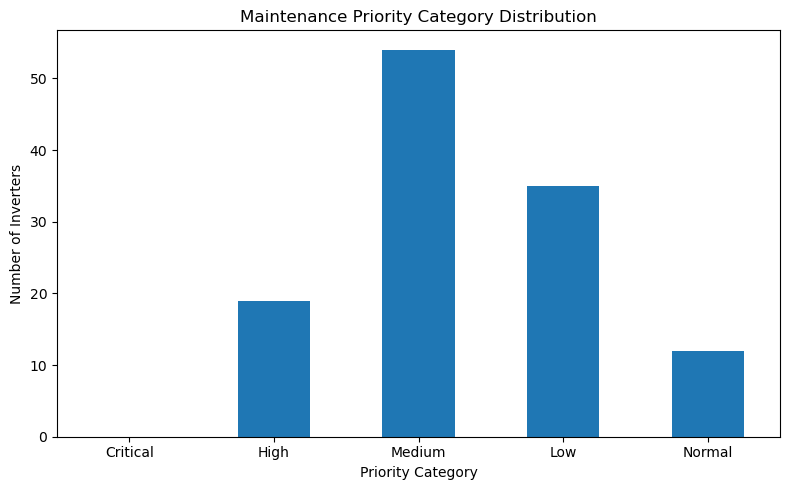

In [32]:
priority_summary = ranked_assets["priority_category"].value_counts().reindex(
    ["Critical", "High", "Medium", "Low", "Normal"], fill_value=0
)

plt.figure(figsize=(8, 5))
priority_summary.plot(kind="bar")
plt.title("Maintenance Priority Category Distribution")
plt.xlabel("Priority Category")
plt.ylabel("Number of Inverters")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 23. Visualisation: Top 10 Priority Assets

This chart shows the highest-priority inverters based on the maintenance priority score.


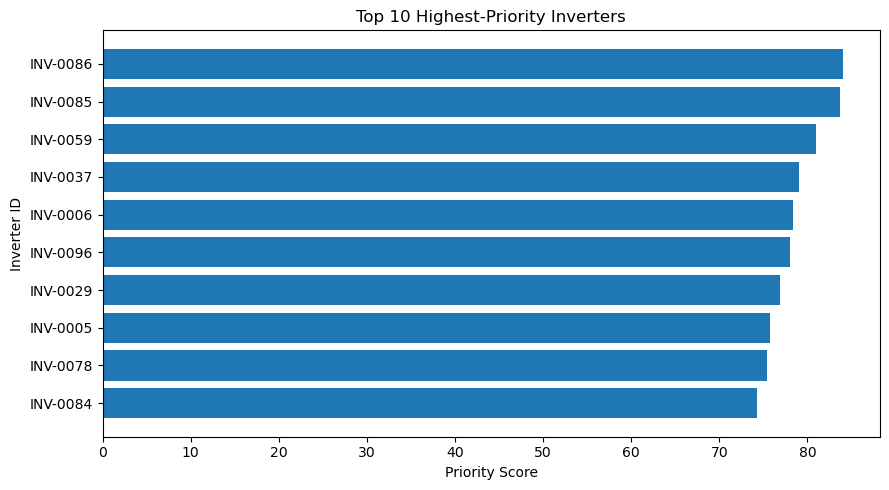

In [33]:
top_10_assets = ranked_assets.head(10).sort_values("priority_score")

plt.figure(figsize=(9, 5))
plt.barh(top_10_assets["inverter_id"], top_10_assets["priority_score"])
plt.title("Top 10 Highest-Priority Inverters")
plt.xlabel("Priority Score")
plt.ylabel("Inverter ID")
plt.tight_layout()
plt.show()


## 24. Visualisation: Scheduled Tasks by Date

This chart shows how many maintenance tasks are scheduled on each day of the planning horizon.


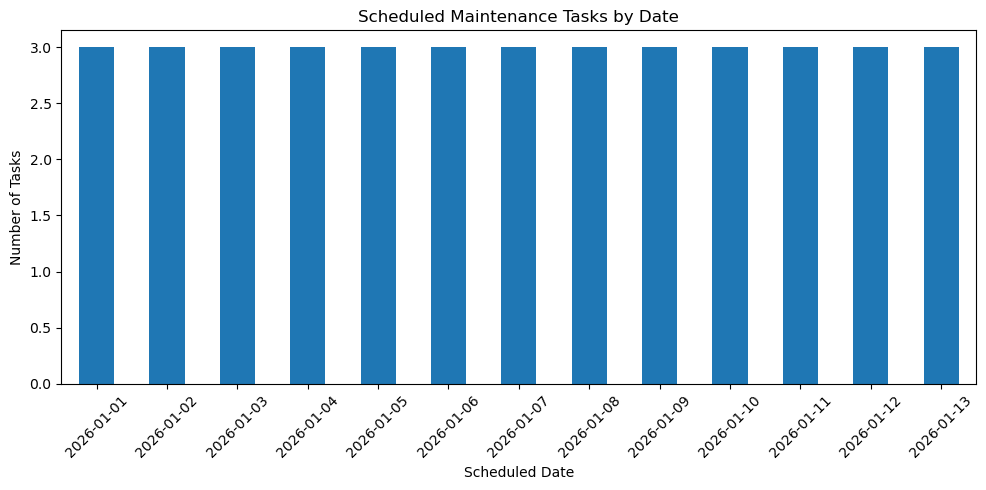

In [34]:
if not schedule_df.empty:
    schedule_counts = schedule_df.groupby("scheduled_date").size()

    plt.figure(figsize=(10, 5))
    schedule_counts.plot(kind="bar")
    plt.title("Scheduled Maintenance Tasks by Date")
    plt.xlabel("Scheduled Date")
    plt.ylabel("Number of Tasks")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No scheduled tasks available for plotting.")


## 25. Visualisation: Cost Comparison

This chart compares the simple baseline schedule against the optimized greedy schedule.


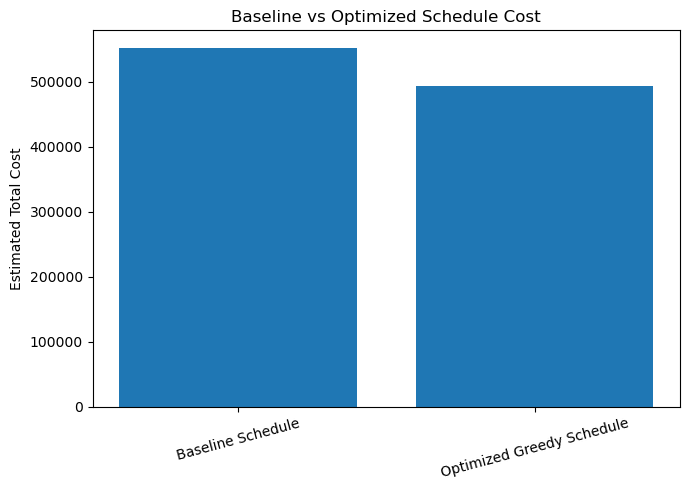

In [35]:
plt.figure(figsize=(7, 5))
plt.bar(cost_summary["Scenario"], cost_summary["Estimated Total Cost"])
plt.title("Baseline vs Optimized Schedule Cost")
plt.ylabel("Estimated Total Cost")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 26. Visualisation: Risk Reduction Over Scheduled Tasks

This chart shows the cumulative failure risk addressed as tasks are scheduled. It helps explain how quickly the schedule reduces operational exposure.


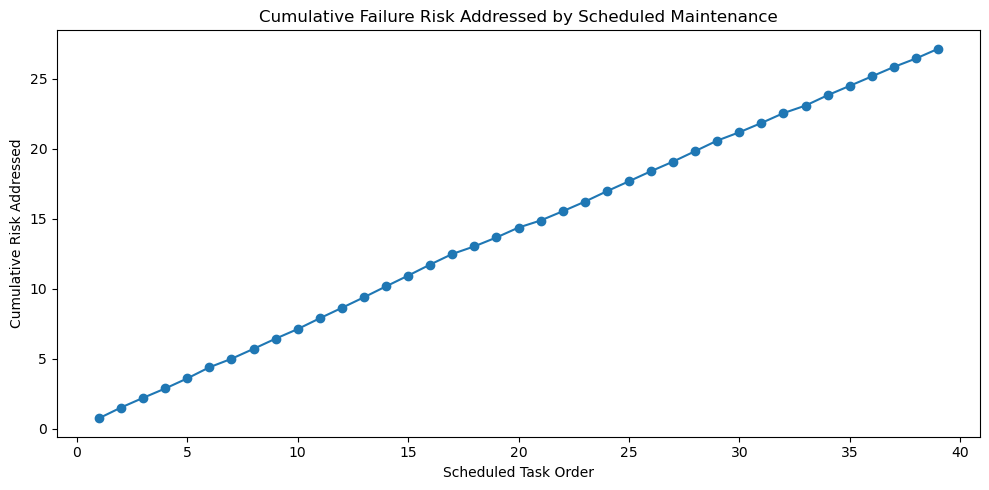

In [36]:
if not schedule_df.empty:
    risk_reduction = schedule_df.sort_values("scheduled_date").copy()
    risk_reduction["cumulative_risk_addressed"] = risk_reduction["failure_probability_30d"].cumsum()

    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(risk_reduction) + 1), risk_reduction["cumulative_risk_addressed"], marker="o")
    plt.title("Cumulative Failure Risk Addressed by Scheduled Maintenance")
    plt.xlabel("Scheduled Task Order")
    plt.ylabel("Cumulative Risk Addressed")
    plt.tight_layout()
    plt.show()
else:
    print("No scheduled tasks available for plotting.")


## 27. Final Outputs

The final outputs are:

1. Ranked maintenance priority table
2. Optimized maintenance schedule
3. Deferred task list

These outputs can be exported as CSV files and attached to documentation or used for dashboard development.


In [37]:
priority_output = ranked_assets[[
    "inverter_id", "manufacturer", "climate_zone", "rated_capacity_kw",
    "priority_score", "priority_category", "failure_probability_30d",
    "rul_days", "anomaly_score", "anomaly_severity", "asset_criticality_score",
    "production_loss_risk", "required_part", "part_status", "required_skill",
    "estimated_repair_hours", "maintenance_cost", "downtime_cost_per_hour"
]].copy()

priority_output.to_csv("maintenance_priority_output.csv", index=False)
schedule_df.to_csv("optimized_maintenance_schedule.csv", index=False)
deferred_df.to_csv("deferred_maintenance_tasks.csv", index=False)

print("Files exported successfully:")
print("- maintenance_priority_output.csv")
print("- optimized_maintenance_schedule.csv")
print("- deferred_maintenance_tasks.csv")


Files exported successfully:
- maintenance_priority_output.csv
- optimized_maintenance_schedule.csv
- deferred_maintenance_tasks.csv


## 28. Final Interpretation

This prototype demonstrates how the Omni-Grid platform can move from prediction to action.

The existing predictive components identify asset risk, degradation, anomaly patterns, and expected remaining useful life. This scheduling module uses those signals to rank assets and create an operationally feasible maintenance schedule.

The key value of this prototype is that it does not only identify risky inverters. It also recommends when they should be serviced, which crew skill is required, what part may be needed, and which tasks should be deferred due to practical constraints.

This supports a more proactive maintenance strategy by helping reduce emergency maintenance, downtime, and inefficient crew allocation.
